In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
from catboost import CatBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("ANALYSIS: Test 2024")
print("="*80)




ANALYSIS: Test 2024


In [61]:
df = pd.read_csv('../data/processed/model_ready/features_no_ytd.csv')

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24875 entries, 0 to 24874
Data columns (total 31 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ATP            24875 non-null  int64  
 1   Location       24875 non-null  object 
 2   Tournament     24875 non-null  object 
 3   Date           24875 non-null  object 
 4   Series         24875 non-null  object 
 5   Court          24875 non-null  object 
 6   Surface        24875 non-null  object 
 7   Round          24875 non-null  object 
 8   Best of        24860 non-null  float64
 9   Winner         24875 non-null  object 
 10  Loser          24875 non-null  object 
 11  WRank          24864 non-null  float64
 12  LRank          24821 non-null  float64
 13  WPts           24865 non-null  float64
 14  LPts           24821 non-null  float64
 15  elo_winner     24875 non-null  float64
 16  elo_loser      24875 non-null  float64
 17  proba_elo      24875 non-null  float64
 18  Winner

## Preprocessing

In [63]:
df['Date'] = pd.to_datetime(df['Date'])
df_24 = df[df['Date'].dt.year == 2024]
print(f"Test: {len(df_24)} rows (2024)")
df_train = df[df['Date'].dt.year != 2024]


Test: 2696 rows (2024)


In [64]:
from pathlib import Path
from sklearn.preprocessing import StandardScaler

def create_normalized_match_id(row):
    """Create same match_id for both perspectives - alphabetically sorted names"""
    date = str(row['Date'])
    p1 = str(row['player_name']).strip().replace(' ', '').replace('.', '')
    p2 = str(row['opponent_name']).strip().replace(' ', '').replace('.', '')
    names_sorted = '_'.join(sorted([p1, p2]))
    return f"{date}_{names_sorted}"

print(f"Original train shape: {df_train.shape}")
print("Format: Winner/Loser (will transform)\n")

def transform_to_player_perspective(df_source):
    """
    Transform match data to player perspective format.
    Each match creates 2 rows: one from each player's perspective.
    """
    
    context_cols = [
        'ATP', 'Location', 'Tournament', 'Date', 'Series', 'Court', 
        'Surface', 'Round', 'Best of', 'Year', 'stats_url', 'duration', 'h2h'
    ]
    context_cols = [c for c in context_cols if c in df_source.columns]
    
    winner_rows = df_source[context_cols].copy()
    winner_rows['player_name'] = df_source['Winner']
    winner_rows['opponent_name'] = df_source['Loser']
    winner_rows['won'] = 1
    winner_rows['player_rank'] = df_source['WRank']
    winner_rows['player_points'] = df_source['WPts']
    winner_rows['player_elo'] = df_source['elo_winner']
    winner_rows['player_h2h'] = df_source['W_h2h']
    winner_rows['opponent_rank'] = df_source['LRank']
    winner_rows['opponent_points'] = df_source['LPts']
    winner_rows['opponent_elo'] = df_source['elo_loser']
    winner_rows['opponent_h2h'] = df_source['L_h2h']
    
    for col in df_source.columns:
        if col.startswith('Winner_') and col != 'Winner':
            new_col = col.replace('Winner_', 'player_')
            winner_rows[new_col] = df_source[col]
        elif col.startswith('Loser_') and col != 'Loser':
            new_col = col.replace('Loser_', 'opponent_')
            winner_rows[new_col] = df_source[col]
        elif col.startswith('winner_') and 'ytd' in col:
            new_col = col.replace('winner_', 'player_')
            winner_rows[new_col] = df_source[col]
        elif col.startswith('loser_') and 'ytd' in col:
            new_col = col.replace('loser_', 'opponent_')
            winner_rows[new_col] = df_source[col]
    
    if 'winner_form' in df_source.columns:
        winner_rows['player_form'] = df_source['winner_form']
        winner_rows['opponent_form'] = df_source['loser_form']
        winner_rows['form_diff'] = df_source['form_diff']
    
    if 'proba_elo' in df_source.columns:
        winner_rows['player_win_prob_elo'] = df_source['proba_elo']
    
    loser_rows = df_source[context_cols].copy()
    loser_rows['player_name'] = df_source['Loser']
    loser_rows['opponent_name'] = df_source['Winner']
    loser_rows['won'] = 0
    loser_rows['player_rank'] = df_source['LRank']
    loser_rows['player_points'] = df_source['LPts']
    loser_rows['player_elo'] = df_source['elo_loser']
    loser_rows['player_h2h'] = df_source['L_h2h']
    loser_rows['opponent_rank'] = df_source['WRank']
    loser_rows['opponent_points'] = df_source['WPts']
    loser_rows['opponent_elo'] = df_source['elo_winner']
    loser_rows['opponent_h2h'] = df_source['W_h2h']
    
    for col in df_source.columns:
        if col.startswith('Loser_') and col != 'Loser':
            new_col = col.replace('Loser_', 'player_')
            loser_rows[new_col] = df_source[col]
        elif col.startswith('Winner_') and col != 'Winner':
            new_col = col.replace('Winner_', 'opponent_')
            loser_rows[new_col] = df_source[col]
        elif col.startswith('loser_') and 'ytd' in col:
            new_col = col.replace('loser_', 'player_')
            loser_rows[new_col] = df_source[col]
        elif col.startswith('winner_') and 'ytd' in col:
            new_col = col.replace('winner_', 'opponent_')
            loser_rows[new_col] = df_source[col]
    
    if 'loser_form' in df_source.columns:
        loser_rows['player_form'] = df_source['loser_form']
        loser_rows['opponent_form'] = df_source['winner_form']
        loser_rows['form_diff'] = -df_source['form_diff']
    
    if 'proba_elo' in df_source.columns:
        loser_rows['player_win_prob_elo'] = 1 - df_source['proba_elo']
    
    df_combined = pd.concat([winner_rows, loser_rows], ignore_index=True)
    
    if 'Date' in df_combined.columns:
        df_combined = df_combined.sort_values('Date').reset_index(drop=True)
    
    return df_combined

print("="*80)
print("TRANSFORMING TRAIN TO PLAYER PERSPECTIVE")
print("="*80)

df_train_transformed = transform_to_player_perspective(df_train)
print(f"✓ Transformed: {df_train_transformed.shape}")
print("✓ Now has player_name, opponent_name, won columns")

print("\n" + "="*80)
print("CREATING NORMALIZED MATCH_ID (TRAIN)")
print("="*80)

df_train_transformed['match_id'] = df_train_transformed.apply(create_normalized_match_id, axis=1)

# Drop duplicated matches while preserving one row per perspective (won=1 and won=0)
rows_before_dedup = len(df_train_transformed)
df_train_transformed = df_train_transformed.drop_duplicates(subset=['match_id', 'won'], keep='first').reset_index(drop=True)
rows_removed = rows_before_dedup - len(df_train_transformed)

print(f"✓ Removed {rows_removed} duplicated perspective rows")
print(f"✓ Created match_id for {df_train_transformed['match_id'].nunique()} unique matches")
print(f"✓ Total rows after dedup: {len(df_train_transformed)}")

match_counts = df_train_transformed['match_id'].value_counts()
both_persp = (match_counts == 2).sum()
one_persp = (match_counts == 1).sum()

print("\nPerspective verification:")
print(f"  Matches with 2 perspectives: {both_persp}")
print(f"  Matches with 1 perspective: {one_persp}")

if both_persp == df_train_transformed['match_id'].nunique():
    print("✓✓✓ PERFECT: paired match_id generated correctly")
else:
    print(f"⚠ Note: {one_persp} matches have only 1 perspective")

ytd_cols_train = [col for col in df_train_transformed.columns if 'ytd' in col.lower()]
if len(ytd_cols_train) > 0:
    print(f"\nDropping {len(ytd_cols_train)} YTD columns")
    df_train_model = df_train_transformed.drop(columns=ytd_cols_train)
else:
    df_train_model = df_train_transformed.copy()

print(f"After dropping YTD: {df_train_model.shape}")

drop_cols_train = [
    'player_name',
    'opponent_name',
    'stats_url',
    'Date',
    'ATP',
    'Tournament',
    'Location'
 ]

drop_cols_train = [col for col in drop_cols_train if col in df_train_model.columns]

print(f"Ready for preprocessing: {df_train_model.shape}")

target_train = 'won'

categorical_cols_train = [
    'Surface',
    'Court',
    'Round',
    'Series',
    'player_hand',
    'opponent_hand',
]
categorical_cols_train = [col for col in categorical_cols_train if col in df_train_model.columns]

numerical_cols_train = [
    col for col in df_train_model.columns
    if col not in categorical_cols_train and col != target_train
]

print(f"\nCategorical columns ({len(categorical_cols_train)}): {categorical_cols_train}")
print(f"Numerical columns ({len(numerical_cols_train)}): {len(numerical_cols_train)} columns")

print("\n" + "="*80)
print("HANDLING CATEGORICAL VALUES (TRAIN)")
print("="*80)

if 'player_hand' in df_train_model.columns:
    df_train_model['player_hand'] = df_train_model['player_hand'].replace('U', 'Unknown')
if 'opponent_hand' in df_train_model.columns:
    df_train_model['opponent_hand'] = df_train_model['opponent_hand'].replace('U', 'Unknown')
if 'Round' in df_train_model.columns:
    df_train_model['Round'] = df_train_model['Round'].replace('Round Robin', '4th Round')
if 'Series' in df_train_model.columns:
    df_train_model['Series'] = df_train_model['Series'].replace('Masters Cup', 'ATP500')

for col in categorical_cols_train:
    if df_train_model[col].isnull().any():
        df_train_model[col] = df_train_model[col].fillna('Unknown')

print("✓ Categorical values handled")

print("\nTemporarily filling numerical NaNs with 0 for feature engineering...")
for col in numerical_cols_train:
    if df_train_model[col].isnull().any():
        df_train_model[col] = df_train_model[col].fillna(0)

print("✓ Temporary fills complete")

print("\n" + "="*80)
print("FEATURE ENGINEERING (TRAIN)")
print("="*80)

if 'player_rank' in df_train_model.columns and 'opponent_rank' in df_train_model.columns:
    df_train_model['rank_diff'] = df_train_model['player_rank'] - df_train_model['opponent_rank']
    print("Created: rank_diff")

if 'player_elo' in df_train_model.columns and 'opponent_elo' in df_train_model.columns:
    df_train_model['elo_diff'] = df_train_model['player_elo'] - df_train_model['opponent_elo']
    print("Created: elo_diff")

if 'player_h2h' in df_train_model.columns and 'opponent_h2h' in df_train_model.columns:
    total_h2h_train = df_train_model['player_h2h'] + df_train_model['opponent_h2h']
    df_train_model['player_h2h_rate'] = np.where(
        total_h2h_train > 0,
        df_train_model['player_h2h'] / total_h2h_train,
        0.5
    )
    print("Created: player_h2h_rate")

if 'player_rating' in df_train_model.columns and 'opponent_rating' in df_train_model.columns:
    df_train_model['rating_diff'] = df_train_model['player_rating'] - df_train_model['opponent_rating']
    print("Created: rating_diff")

if 'player_height' in df_train_model.columns and 'opponent_height' in df_train_model.columns:
    df_train_model['height_diff'] = df_train_model['player_height'] - df_train_model['opponent_height']
    print("Created: height_diff")

if 'player_points' in df_train_model.columns and 'opponent_points' in df_train_model.columns:
    df_train_model['points_diff'] = df_train_model['player_points'] - df_train_model['opponent_points']
    print("Created: points_diff")

if 'player_age' in df_train_model.columns and 'opponent_age' in df_train_model.columns:
    df_train_model['age_diff'] = df_train_model['player_age'] - df_train_model['opponent_age']
    print("Created: age_diff")

if 'player_rank' in df_train_model.columns and 'opponent_rank' in df_train_model.columns:
    df_train_model['proba_rank_200'] = 1 / (1 + 10 ** ((df_train_model['player_rank'] - df_train_model['opponent_rank']) / 200))
    print("Created: proba_rank_200")

if 'player_form' in df_train_model.columns and 'opponent_form' in df_train_model.columns:
    df_train_model['proba_form_50'] = 1 / (1 + 10 ** ((df_train_model['player_form'] - df_train_model['opponent_form']) / 50))
    print("Created: proba_form_50")

print(f"\nFinal train shape with engineered features: {df_train_model.shape}")

print("\n" + "="*80)
print("ENCODING CATEGORICAL VARIABLES (TRAIN)")
print("="*80)

df_train_encoded = pd.get_dummies(df_train_model, columns=categorical_cols_train, drop_first=True)

print(f"\nShape after encoding: {df_train_encoded.shape}")
print(f"Added {df_train_encoded.shape[1] - df_train_model.shape[1] + len(categorical_cols_train)} dummy variables")

X_train = df_train_encoded.drop(columns=[target_train])
X_train_not_encoded = df_train_model.drop(columns=[target_train])
y_train = df_train_model[target_train]

train_identifiers = X_train[['Tournament', 'Date', 'player_name', 'opponent_name']].copy()

cols_to_remove_train = ['match_id'] + drop_cols_train
cols_to_remove_train = [c for c in cols_to_remove_train if c in X_train.columns]
X_train_full = X_train.drop(columns=cols_to_remove_train, axis=1)

cols_to_remove_train_not_encoded = ['match_id'] + drop_cols_train
cols_to_remove_train_not_encoded = [c for c in cols_to_remove_train_not_encoded if c in X_train_not_encoded.columns]
X_train_full_not_encoded = X_train_not_encoded.drop(columns=cols_to_remove_train_not_encoded, axis=1)

print("\n" + "="*80)
print("FILLING NUMERICAL MISSING VALUES (TRAIN)")
print("="*80)

numerical_cols_in_X_train = X_train_full.select_dtypes(include=[np.number]).columns
train_medians = {}
for col in numerical_cols_in_X_train:
    if X_train_full[col].isnull().any():
        train_medians[col] = X_train_full[col].median()

for col, median_val in train_medians.items():
    X_train_full[col] = X_train_full[col].fillna(median_val)
    print(f"  {col}: filled with {median_val:.2f}")

train_missing = X_train_full.isnull().sum().sum()
print("\nRemaining missing:")
print(f"  Train dataset: {train_missing}")

if train_missing == 0:
    print("✓ All missing values filled")

print("\n" + "="*80)
print("FEATURE SCALING (TRAIN)")
print("="*80)

cols_to_scale_train = [
    col for col in X_train_full.columns
    if not any(cat in col for cat in categorical_cols_train)
]

scaler_train = StandardScaler()
X_train_full_scaled = X_train_full.copy()
X_train_full_scaled[cols_to_scale_train] = scaler_train.fit_transform(X_train_full[cols_to_scale_train])

print("\nScaling complete.")

print("\n" + "="*80)
print("PREPROCESSING COMPLETE (TRAIN)")
print("="*80)

print("\nFinal train dataset:")
print(f"  Total samples: {len(X_train_full):,}")
print(f"  Total features: {X_train_full.shape[1]:,}")
print(f"  Target balance: {y_train.mean():.1%} won")

print("\nReady for modeling!")
print("\nYou now have:")
print("  X_train_full, y_train - Original scale")
print("  X_train_full_scaled - Scaled features")
print("  X_train_full_not_encoded - Not encoded")

Original train shape: (22179, 31)
Format: Winner/Loser (will transform)

TRANSFORMING TRAIN TO PLAYER PERSPECTIVE
✓ Transformed: (44358, 32)
✓ Now has player_name, opponent_name, won columns

CREATING NORMALIZED MATCH_ID (TRAIN)
✓ Removed 20 duplicated perspective rows
✓ Created match_id for 22169 unique matches
✓ Total rows after dedup: 44338

Perspective verification:
  Matches with 2 perspectives: 22169
  Matches with 1 perspective: 0
✓✓✓ PERFECT: paired match_id generated correctly
After dropping YTD: (44338, 33)
Ready for preprocessing: (44338, 33)

Categorical columns (6): ['Surface', 'Court', 'Round', 'Series', 'player_hand', 'opponent_hand']
Numerical columns (26): 26 columns

HANDLING CATEGORICAL VALUES (TRAIN)
✓ Categorical values handled

Temporarily filling numerical NaNs with 0 for feature engineering...
✓ Temporary fills complete

FEATURE ENGINEERING (TRAIN)
Created: rank_diff
Created: elo_diff
Created: player_h2h_rate
Created: rating_diff
Created: height_diff
Created: po

In [65]:
from pathlib import Path
from sklearn.preprocessing import StandardScaler

def create_normalized_match_id(row):
    """Create same match_id for both perspectives - alphabetically sorted names"""
    date = str(row['Date'])
    p1 = str(row['player_name']).strip().replace(' ', '').replace('.', '')
    p2 = str(row['opponent_name']).strip().replace(' ', '').replace('.', '')
    names_sorted = '_'.join(sorted([p1, p2]))
    return f"{date}_{names_sorted}"

print(f"Original shape: {df_24.shape}")
print("Format: Winner/Loser (will transform)\n")

def transform_to_player_perspective(df_source):
    """
    Transform match data to player perspective format.
    Each match creates 2 rows: one from each player's perspective.
    """
    
    context_cols = [
        'ATP', 'Location', 'Tournament', 'Date', 'Series', 'Court', 
        'Surface', 'Round', 'Best of', 'Year', 'stats_url', 'duration', 'h2h'
    ]
    context_cols = [c for c in context_cols if c in df_source.columns]
    
    winner_rows = df_source[context_cols].copy()
    winner_rows['player_name'] = df_source['Winner']
    winner_rows['opponent_name'] = df_source['Loser']
    winner_rows['won'] = 1
    winner_rows['player_rank'] = df_source['WRank']
    winner_rows['player_points'] = df_source['WPts']
    winner_rows['player_elo'] = df_source['elo_winner']
    winner_rows['player_h2h'] = df_source['W_h2h']
    winner_rows['opponent_rank'] = df_source['LRank']
    winner_rows['opponent_points'] = df_source['LPts']
    winner_rows['opponent_elo'] = df_source['elo_loser']
    winner_rows['opponent_h2h'] = df_source['L_h2h']
    
    for col in df_source.columns:
        if col.startswith('Winner_') and col != 'Winner':
            new_col = col.replace('Winner_', 'player_')
            winner_rows[new_col] = df_source[col]
        elif col.startswith('Loser_') and col != 'Loser':
            new_col = col.replace('Loser_', 'opponent_')
            winner_rows[new_col] = df_source[col]
        elif col.startswith('winner_') and 'ytd' in col:
            new_col = col.replace('winner_', 'player_')
            winner_rows[new_col] = df_source[col]
        elif col.startswith('loser_') and 'ytd' in col:
            new_col = col.replace('loser_', 'opponent_')
            winner_rows[new_col] = df_source[col]
    
    if 'winner_form' in df_source.columns:
        winner_rows['player_form'] = df_source['winner_form']
        winner_rows['opponent_form'] = df_source['loser_form']
        winner_rows['form_diff'] = df_source['form_diff']
    
    if 'proba_elo' in df_source.columns:
        winner_rows['player_win_prob_elo'] = df_source['proba_elo']
    
    loser_rows = df_source[context_cols].copy()
    loser_rows['player_name'] = df_source['Loser']
    loser_rows['opponent_name'] = df_source['Winner']
    loser_rows['won'] = 0
    loser_rows['player_rank'] = df_source['LRank']
    loser_rows['player_points'] = df_source['LPts']
    loser_rows['player_elo'] = df_source['elo_loser']
    loser_rows['player_h2h'] = df_source['L_h2h']
    loser_rows['opponent_rank'] = df_source['WRank']
    loser_rows['opponent_points'] = df_source['WPts']
    loser_rows['opponent_elo'] = df_source['elo_winner']
    loser_rows['opponent_h2h'] = df_source['W_h2h']
    
    for col in df_source.columns:
        if col.startswith('Loser_') and col != 'Loser':
            new_col = col.replace('Loser_', 'player_')
            loser_rows[new_col] = df_source[col]
        elif col.startswith('Winner_') and col != 'Winner':
            new_col = col.replace('Winner_', 'opponent_')
            loser_rows[new_col] = df_source[col]
        elif col.startswith('loser_') and 'ytd' in col:
            new_col = col.replace('loser_', 'player_')
            loser_rows[new_col] = df_source[col]
        elif col.startswith('winner_') and 'ytd' in col:
            new_col = col.replace('winner_', 'opponent_')
            loser_rows[new_col] = df_source[col]
    
    if 'loser_form' in df_source.columns:
        loser_rows['player_form'] = df_source['loser_form']
        loser_rows['opponent_form'] = df_source['winner_form']
        loser_rows['form_diff'] = -df_source['form_diff']
    
    if 'proba_elo' in df_source.columns:
        loser_rows['player_win_prob_elo'] = 1 - df_source['proba_elo']
    
    df_combined = pd.concat([winner_rows, loser_rows], ignore_index=True)
    
    if 'Date' in df_combined.columns:
        df_combined = df_combined.sort_values('Date').reset_index(drop=True)
    
    return df_combined

print("="*80)
print("TRANSFORMING TO PLAYER PERSPECTIVE")
print("="*80)

df_transformed = transform_to_player_perspective(df_24)
print(f"✓ Transformed: {df_transformed.shape}")
print("✓ Now has player_name, opponent_name, won columns")

print("\n" + "="*80)
print("CREATING NORMALIZED MATCH_ID")
print("="*80)

df_transformed['match_id'] = df_transformed.apply(create_normalized_match_id, axis=1)

# Drop duplicated matches while preserving one row per perspective (won=1 and won=0)
rows_before_dedup = len(df_transformed)
df_transformed = df_transformed.drop_duplicates(subset=['match_id', 'won'], keep='first').reset_index(drop=True)
rows_removed = rows_before_dedup - len(df_transformed)

print(f"✓ Removed {rows_removed} duplicated perspective rows")
print(f"✓ Created match_id for {df_transformed['match_id'].nunique()} unique matches")
print(f"✓ Total rows after dedup: {len(df_transformed)}")

match_counts = df_transformed['match_id'].value_counts()
both_persp = (match_counts == 2).sum()
one_persp = (match_counts == 1).sum()

print("\nPerspective verification:")
print(f"  Matches with 2 perspectives: {both_persp}")
print(f"  Matches with 1 perspective: {one_persp}")

if both_persp == df_transformed['match_id'].nunique():
    print("✓✓✓ PERFECT: paired match_id generated correctly")
else:
    print(f"⚠ Note: {one_persp} matches have only 1 perspective")

ytd_cols = [col for col in df_transformed.columns if 'ytd' in col.lower()]
if len(ytd_cols) > 0:
    print(f"\nDropping {len(ytd_cols)} YTD columns")
    df_model = df_transformed.drop(columns=ytd_cols)
else:
    df_model = df_transformed.copy()

print(f"After dropping YTD: {df_model.shape}")

drop_cols = [
    'player_name',
    'opponent_name',
    'stats_url',
    'Date',
    'ATP',
    'Tournament',
    'Location'
 ]

drop_cols = [col for col in drop_cols if col in df_model.columns]

print(f"Ready for preprocessing: {df_model.shape}")

target = 'won'

categorical_cols = [
    'Surface',
    'Court',
    'Round',
    'Series',
    'player_hand',
    'opponent_hand',
]
categorical_cols = [col for col in categorical_cols if col in df_model.columns]

numerical_cols = [
    col for col in df_model.columns
    if col not in categorical_cols and col != target
]

print(f"\nCategorical columns ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical columns ({len(numerical_cols)}): {len(numerical_cols)} columns")

print("\n" + "="*80)
print("HANDLING CATEGORICAL VALUES")
print("="*80)

if 'player_hand' in df_model.columns:
    df_model['player_hand'] = df_model['player_hand'].replace('U', 'Unknown')
if 'opponent_hand' in df_model.columns:
    df_model['opponent_hand'] = df_model['opponent_hand'].replace('U', 'Unknown')
if 'Round' in df_model.columns:
    df_model['Round'] = df_model['Round'].replace('Round Robin', '4th Round')
if 'Series' in df_model.columns:
    df_model['Series'] = df_model['Series'].replace('Masters Cup', 'ATP500')

for col in categorical_cols:
    if df_model[col].isnull().any():
        df_model[col] = df_model[col].fillna('Unknown')

print("✓ Categorical values handled")

print("\nTemporarily filling numerical NaNs with 0 for feature engineering...")
for col in numerical_cols:
    if df_model[col].isnull().any():
        df_model[col] = df_model[col].fillna(0)

print("✓ Temporary fills complete")

print("\n" + "="*80)
print("FEATURE ENGINEERING")
print("="*80)

if 'player_rank' in df_model.columns and 'opponent_rank' in df_model.columns:
    df_model['rank_diff'] = df_model['player_rank'] - df_model['opponent_rank']
    print("Created: rank_diff")

if 'player_elo' in df_model.columns and 'opponent_elo' in df_model.columns:
    df_model['elo_diff'] = df_model['player_elo'] - df_model['opponent_elo']
    print("Created: elo_diff")

if 'player_h2h' in df_model.columns and 'opponent_h2h' in df_model.columns:
    total_h2h = df_model['player_h2h'] + df_model['opponent_h2h']
    df_model['player_h2h_rate'] = np.where(
        total_h2h > 0,
        df_model['player_h2h'] / total_h2h,
        0.5
    )
    print("Created: player_h2h_rate")

if 'player_rating' in df_model.columns and 'opponent_rating' in df_model.columns:
    df_model['rating_diff'] = df_model['player_rating'] - df_model['opponent_rating']
    print("Created: rating_diff")

if 'player_height' in df_model.columns and 'opponent_height' in df_model.columns:
    df_model['height_diff'] = df_model['player_height'] - df_model['opponent_height']
    print("Created: height_diff")

if 'player_points' in df_model.columns and 'opponent_points' in df_model.columns:
    df_model['points_diff'] = df_model['player_points'] - df_model['opponent_points']
    print("Created: points_diff")

if 'player_age' in df_model.columns and 'opponent_age' in df_model.columns:
    df_model['age_diff'] = df_model['player_age'] - df_model['opponent_age']
    print("Created: age_diff")

if 'player_rank' in df_model.columns and 'opponent_rank' in df_model.columns:
    df_model['proba_rank_200'] = 1 / (1 + 10 ** ((df_model['player_rank'] - df_model['opponent_rank']) / 200))
    print("Created: proba_rank_200")

if 'player_form' in df_model.columns and 'opponent_form' in df_model.columns:
    df_model['proba_form_50'] = 1 / (1 + 10 ** ((df_model['player_form'] - df_model['opponent_form']) / 50))
    print("Created: proba_form_50")

df_right = df_model.drop([target], axis=1)

print(f"\nFinal shape with engineered features: {df_model.shape}")

print("\n" + "="*80)
print("ENCODING CATEGORICAL VARIABLES")
print("="*80)

df_encoded = pd.get_dummies(df_model, columns=categorical_cols, drop_first=True)

print(f"\nShape after encoding: {df_encoded.shape}")
print(f"Added {df_encoded.shape[1] - df_model.shape[1] + len(categorical_cols)} dummy variables")

#df_to_export = df_encoded[df_encoded['won'] == 1]
#out_path = Path('../data/processed/model_ready/features_final_2024.csv')
#out_path.parent.mkdir(parents=True, exist_ok=True)
#df_to_export.to_csv(out_path, index=False)
#print("Exported finalized dataset to 'features_final_2024.csv'")

X = df_encoded.drop(columns=[target])
X_not_encoded = df_model.drop(columns=[target])
y = df_model[target]

tournaments_date = X[['Tournament','Date', 'player_name', 'opponent_name']].copy()

cols_to_remove = ['match_id'] + drop_cols
cols_to_remove = [c for c in cols_to_remove if c in X.columns]
X_full = X.drop(columns=cols_to_remove, axis=1)

cols_to_remove_not_encoded = ['match_id'] + drop_cols
cols_to_remove_not_encoded = [c for c in cols_to_remove_not_encoded if c in X_not_encoded.columns]
X_full_not_encoded = X_not_encoded.drop(columns=cols_to_remove_not_encoded, axis=1)

print("\n" + "="*80)
print("FILLING NUMERICAL MISSING VALUES (Full df_24)")
print("="*80)

numerical_cols_in_X = X_full.select_dtypes(include=[np.number]).columns
full_medians = {}
for col in numerical_cols_in_X:
    if X_full[col].isnull().any():
        full_medians[col] = X_full[col].median()

for col, median_val in full_medians.items():
    X_full[col] = X_full[col].fillna(median_val)
    print(f"  {col}: filled with {median_val:.2f}")

full_missing = X_full.isnull().sum().sum()
print("\nRemaining missing:")
print(f"  Full dataset: {full_missing}")

if full_missing == 0:
    print("✓ All missing values filled")

print("\n" + "="*80)
print("FEATURE SCALING")
print("="*80)

cols_to_scale = [
    col for col in X_full.columns
    if not any(cat in col for cat in categorical_cols)
]

proba_cols = [col for col in cols_to_scale if 'proba_' in col or col == 'player_win_prob_elo']

cols_to_scale_final = cols_to_scale
print(f"\nUsing OPTION A: Scaling ALL {len(cols_to_scale_final)} columns")
print("  (Probabilities will be scaled too)")

scaler = StandardScaler()
X_full_scaled = X_full.copy()
X_full_scaled[cols_to_scale_final] = scaler.fit_transform(X_full[cols_to_scale_final])

print("\nScaling complete.")

print("\n" + "="*80)
print("PREPROCESSING COMPLETE (FULL df_24)")
print("="*80)

print("\nFinal dataset:")
print(f"  Total samples: {len(X_full):,}")
print(f"  Total features: {X_full.shape[1]:,}")
print(f"  Target balance: {y.mean():.1%} won")

print("\nReady for modeling!")
print("\nYou now have:")
print("  X_full, y - Original scale")
print("  X_full_scaled - Scaled features")
print("  X_full_not_encoded - Not encoded")

Original shape: (2696, 31)
Format: Winner/Loser (will transform)

TRANSFORMING TO PLAYER PERSPECTIVE
✓ Transformed: (5392, 32)
✓ Now has player_name, opponent_name, won columns

CREATING NORMALIZED MATCH_ID
✓ Removed 2 duplicated perspective rows
✓ Created match_id for 2695 unique matches
✓ Total rows after dedup: 5390

Perspective verification:
  Matches with 2 perspectives: 2695
  Matches with 1 perspective: 0
✓✓✓ PERFECT: paired match_id generated correctly
After dropping YTD: (5390, 33)
Ready for preprocessing: (5390, 33)

Categorical columns (6): ['Surface', 'Court', 'Round', 'Series', 'player_hand', 'opponent_hand']
Numerical columns (26): 26 columns

HANDLING CATEGORICAL VALUES
✓ Categorical values handled

Temporarily filling numerical NaNs with 0 for feature engineering...
✓ Temporary fills complete

FEATURE ENGINEERING
Created: rank_diff
Created: elo_diff
Created: player_h2h_rate
Created: rating_diff
Created: height_diff
Created: points_diff
Created: age_diff
Created: proba_r

## Run the model

In [66]:
import pickle
with open("../models/catboost_model.pkl",'rb') as m:
    model = pickle.load(m)

In [67]:
y_pred = model.predict(X_full)
y_proba = model.predict_proba(X_full)[:, 1]
acc = accuracy_score(y, y_pred) 
print(acc)

0.7441558441558441


In [68]:
tournament_pred = pd.DataFrame({'Tournament':tournaments_date['Tournament'],
                                'Date':tournaments_date['Date'], 'player_name':tournaments_date['player_name'], 
                                'opponent_name':tournaments_date['opponent_name'],'Won':y, 'Prediction':y_pred, 
                                'Model_Prob':y_proba})
tournament_pred

,Tournament,Date,player_name,opponent_name,Won,Prediction,Model_Prob
0,Brisbane International,2024-01-01,Dimitrov G.,Murray A.,1,1,0.699488
1,Brisbane International,2024-01-01,Murray A.,Dimitrov G.,0,0,0.316532
2,Hong Kong Tennis Open,2024-01-01,Mochizuki S.,Van De Zandschulp B.,0,0,0.051341
3,Hong Kong Tennis Open,2024-01-01,Djere L.,Shang J.,0,0,0.035557
4,Hong Kong Tennis Open,2024-01-01,Bonzi B.,Ruusuvuori E.,0,0,0.054437
...,...,...,...,...,...,...,...
5385,Masters Cup,2024-11-16,Sinner J.,Ruud C.,1,1,0.646741
5386,Masters Cup,2024-11-16,Zverev A.,Fritz T.,0,0,0.295944
5387,Masters Cup,2024-11-16,Ruud C.,Sinner J.,0,0,0.401784
5388,Masters Cup,2024-11-17,Sinner J.,Fritz T.,1,1,0.931069


## Attach odds and Filtering for 2024 Wimbledon 
- Final Dataset for testing betting strategies: **pred_with_odds**

In [69]:
import sys
import os
sys.path.append(os.path.abspath("../src"))
from betting_func import create_normalized_match_id_winner_loser,create_normalized_match_id_player,create_normalized_match_id_winner

In [70]:
df_with_odds = pd.read_csv("../data/processed/model_ready/result.csv")

In [71]:
df_right['match_id_normalized'] = df_right.apply(create_normalized_match_id_player, axis=1)
tournament_pred['match_id_normalized'] = tournament_pred.apply(create_normalized_match_id_player, axis=1)

In [72]:

pred_with_odds = pd.merge(tournament_pred, 
                        df_with_odds[['match_id', 'B365W', 'B365L', 'PSW', 'PSL', 'MaxW', 'MaxL', 'AvgW', 'AvgL']],
                        left_on='match_id_normalized', right_on='match_id', how='left')
pred_with_odds.rename({'player_name': 'Player', 'opponent_name': 'Opponent'}, axis=1, inplace=True)

In [73]:
pred_with_odds

,Tournament,Date,Player,Opponent,Won,Prediction,Model_Prob,match_id_normalized,match_id,B365W,B365L,PSW,PSL,MaxW,MaxL,AvgW,AvgL
0,Brisbane International,2024-01-01,Dimitrov G.,Murray A.,1,1,0.699488,2024-01-01_DimitrovG_MurrayA,2024-01-01_DimitrovG_MurrayA,1.33,3.40,1.35,3.47,1.36,3.50,1.33,3.25
1,Brisbane International,2024-01-01,Murray A.,Dimitrov G.,0,0,0.316532,2024-01-01_DimitrovG_MurrayA,2024-01-01_DimitrovG_MurrayA,1.33,3.40,1.35,3.47,1.36,3.50,1.33,3.25
2,Hong Kong Tennis Open,2024-01-01,Mochizuki S.,Van De Zandschulp B.,0,0,0.051341,2024-01-01_MochizukiS_VanDeZandschulpB,2024-01-01_MochizukiS_VanDeZandschulpB,1.30,3.50,1.28,4.06,1.33,4.06,1.30,3.48
3,Hong Kong Tennis Open,2024-01-01,Djere L.,Shang J.,0,0,0.035557,2024-01-01_DjereL_ShangJ,2024-01-01_DjereL_ShangJ,2.30,1.62,2.07,1.83,2.30,1.83,2.13,1.70
4,Hong Kong Tennis Open,2024-01-01,Bonzi B.,Ruusuvuori E.,0,0,0.054437,2024-01-01_BonziB_RuusuvuoriE,2024-01-01_BonziB_RuusuvuoriE,1.62,2.30,1.58,2.53,1.60,2.60,1.55,2.38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5387,Masters Cup,2024-11-16,Sinner J.,Ruud C.,1,1,0.646741,2024-11-16_RuudC_SinnerJ,2024-11-16_RuudC_SinnerJ,1.05,11.00,1.06,12.48,1.07,12.48,1.05,9.58
5388,Masters Cup,2024-11-16,Zverev A.,Fritz T.,0,0,0.295944,2024-11-16_FritzT_ZverevA,2024-11-16_FritzT_ZverevA,3.00,1.40,2.85,1.48,3.11,1.49,2.94,1.40
5389,Masters Cup,2024-11-16,Ruud C.,Sinner J.,0,0,0.401784,2024-11-16_RuudC_SinnerJ,2024-11-16_RuudC_SinnerJ,1.05,11.00,1.06,12.48,1.07,12.48,1.05,9.58
5390,Masters Cup,2024-11-17,Sinner J.,Fritz T.,1,1,0.931069,2024-11-17_FritzT_SinnerJ,2024-11-17_FritzT_SinnerJ,1.14,5.50,1.17,5.24,1.20,5.70,1.15,5.22


## Deploying betting strategy

In [74]:
# ============================================================================
# ADD MARKET ANALYSIS COLUMNS 
# ============================================================================

pred_with_odds['Market_Prob'] = np.where(
    pred_with_odds['Won'] == 1,
    1 / pred_with_odds['AvgW'],  # Winner perspective: use winner odds
    1 / pred_with_odds['AvgL']   # Loser perspective: use loser odds
)

pred_with_odds['edge'] = pred_with_odds['Model_Prob'] - pred_with_odds['Market_Prob']
print(f"✓ Calculated market_prob, model_prob, edge")


# ============================================================================
# VERIFICATION
# ============================================================================

# Remove rows without odds
pred_with_odds_clean = pred_with_odds[pred_with_odds['AvgW'].notna() & pred_with_odds['AvgL'].notna()].copy()

print(f"\nTotal merged: {len(pred_with_odds)} rows")
print(f"With odds: {len(pred_with_odds_clean)} rows")
print(f"Missing odds: {len(pred_with_odds) - len(pred_with_odds_clean)}")

print(f"\nCleaned dataset:")
print(f"  Winners: {(pred_with_odds_clean['Won']==1).sum()}")
print(f"  Losers: {(pred_with_odds_clean['Won']==0).sum()}")

print(f"\nModel prob averages:")
print(f"  Overall: {pred_with_odds_clean['Model_Prob'].mean():.3f} (should be ~0.50)")
print(f"  Winners: {pred_with_odds_clean[pred_with_odds_clean['Won']==1]['Model_Prob'].mean():.3f} (should be 0.68-0.75)")
print(f"  Losers: {pred_with_odds_clean[pred_with_odds_clean['Won']==0]['Model_Prob'].mean():.3f} (should be 0.25-0.32)")

# LOG LOSS COMPARISON
from sklearn.metrics import log_loss

model_ll = log_loss(pred_with_odds_clean['Won'], pred_with_odds_clean['Model_Prob'])
market_ll = log_loss(pred_with_odds_clean['Won'], pred_with_odds_clean['Market_Prob'])

print(f"\nModel log loss: {model_ll:.4f}")
print(f"Market log loss: {market_ll:.4f}")
improvement = ((market_ll - model_ll) / market_ll) * 100
print(f"Improvement: {improvement:+.1f}%")

pred_with_odds = pred_with_odds_clean.copy()

✓ Calculated market_prob, model_prob, edge

Total merged: 5392 rows
With odds: 5392 rows
Missing odds: 0

Cleaned dataset:
  Winners: 2696
  Losers: 2696

Model prob averages:
  Overall: 0.500 (should be ~0.50)
  Winners: 0.644 (should be 0.68-0.75)
  Losers: 0.356 (should be 0.25-0.32)

Model log loss: 0.5051
Market log loss: 0.5857
Improvement: +13.8%


In [75]:
pred_with_odds

,Tournament,Date,Player,Opponent,Won,Prediction,Model_Prob,match_id_normalized,match_id,B365W,B365L,PSW,PSL,MaxW,MaxL,AvgW,AvgL,Market_Prob,edge
0,Brisbane International,2024-01-01,Dimitrov G.,Murray A.,1,1,0.699488,2024-01-01_DimitrovG_MurrayA,2024-01-01_DimitrovG_MurrayA,1.33,3.40,1.35,3.47,1.36,3.50,1.33,3.25,0.751880,-0.052392
1,Brisbane International,2024-01-01,Murray A.,Dimitrov G.,0,0,0.316532,2024-01-01_DimitrovG_MurrayA,2024-01-01_DimitrovG_MurrayA,1.33,3.40,1.35,3.47,1.36,3.50,1.33,3.25,0.307692,0.008840
2,Hong Kong Tennis Open,2024-01-01,Mochizuki S.,Van De Zandschulp B.,0,0,0.051341,2024-01-01_MochizukiS_VanDeZandschulpB,2024-01-01_MochizukiS_VanDeZandschulpB,1.30,3.50,1.28,4.06,1.33,4.06,1.30,3.48,0.287356,-0.236016
3,Hong Kong Tennis Open,2024-01-01,Djere L.,Shang J.,0,0,0.035557,2024-01-01_DjereL_ShangJ,2024-01-01_DjereL_ShangJ,2.30,1.62,2.07,1.83,2.30,1.83,2.13,1.70,0.588235,-0.552678
4,Hong Kong Tennis Open,2024-01-01,Bonzi B.,Ruusuvuori E.,0,0,0.054437,2024-01-01_BonziB_RuusuvuoriE,2024-01-01_BonziB_RuusuvuoriE,1.62,2.30,1.58,2.53,1.60,2.60,1.55,2.38,0.420168,-0.365731
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5387,Masters Cup,2024-11-16,Sinner J.,Ruud C.,1,1,0.646741,2024-11-16_RuudC_SinnerJ,2024-11-16_RuudC_SinnerJ,1.05,11.00,1.06,12.48,1.07,12.48,1.05,9.58,0.952381,-0.305640
5388,Masters Cup,2024-11-16,Zverev A.,Fritz T.,0,0,0.295944,2024-11-16_FritzT_ZverevA,2024-11-16_FritzT_ZverevA,3.00,1.40,2.85,1.48,3.11,1.49,2.94,1.40,0.714286,-0.418341
5389,Masters Cup,2024-11-16,Ruud C.,Sinner J.,0,0,0.401784,2024-11-16_RuudC_SinnerJ,2024-11-16_RuudC_SinnerJ,1.05,11.00,1.06,12.48,1.07,12.48,1.05,9.58,0.104384,0.297400
5390,Masters Cup,2024-11-17,Sinner J.,Fritz T.,1,1,0.931069,2024-11-17_FritzT_SinnerJ,2024-11-17_FritzT_SinnerJ,1.14,5.50,1.17,5.24,1.20,5.70,1.15,5.22,0.869565,0.061504


### Betting
- Produce a "betting_df" for betting from "pred_with_odds"

In [76]:
betting_df = pred_with_odds.loc[:, ~pred_with_odds.columns.duplicated()].copy()
betting_df = pred_with_odds.reset_index(drop=True)
print(f"Cleaned: {betting_df.shape}")
print(f"Columns: {betting_df.columns.tolist()}")

betting_df.rename({'Model_Prob': 'model_prob', 'Market_Prob': 'market_prob'}, 
                  axis=1, inplace=True)
betting_df['actual_outcome'] = betting_df['Won'].copy()

# Decimal odds
betting_df['decimal_odds'] = np.where(
    betting_df['actual_outcome'] == 1,
    betting_df['AvgW'],
    betting_df['AvgL']
)

betting_df = betting_df.drop_duplicates(subset=['match_id'], keep='first', ignore_index=True)

required = ['actual_outcome', 'model_prob', 'market_prob', 'AvgW', 'AvgL', 'Won','decimal_odds']
missing = [c for c in required if c not in betting_df.columns]
if missing:
    print(f"Missing columns: {missing}")
else:
    print("✓ All required columns present")

betting_df.to_csv("../data/streamlit_data/betting_df_for_streamlit.csv", index=False)

Cleaned: (5392, 19)
Columns: ['Tournament', 'Date', 'Player', 'Opponent', 'Won', 'Prediction', 'Model_Prob', 'match_id_normalized', 'match_id', 'B365W', 'B365L', 'PSW', 'PSL', 'MaxW', 'MaxL', 'AvgW', 'AvgL', 'Market_Prob', 'edge']
✓ All required columns present



SIMULATION 1: FIXED STAKE BETTING - MULTIPLE THRESHOLDS

 Threshold     Bets       Profit      ROI   Win Rate   Sharpe     Max DD
-------------------------------------------------------------------------------------
      0.01       47 $     640.00   13.62%     57.4%    1.85 $   900.00
      0.02       46 $     578.00   12.57%     56.5%    1.69 $   900.00
      0.03       42 $     852.00   20.29%     59.5%    2.69 $   700.00
      0.05       37 $    1234.00   33.35%     64.9%    4.40 $   500.00
      0.08       34 $     785.00   23.09%     61.8%    3.08 $   500.00
      0.10       30 $     758.00   25.27%     60.0%    3.22 $   500.00
      0.12       27 $     751.00   27.81%     59.3%    3.43 $   400.00


      0.15       24 $    1051.00   43.79%     66.7%    5.44 $   400.00
      0.20       16 $     919.00   57.44%     75.0%    8.14 $   300.00

✓ Best ROI: threshold=0.20, ROI=57.44%, Bets=16
✓ Best Sharpe: threshold=0.15, Sharpe=5.44, Bets=24

SIMULATION 2: KELLY CRITERION ANALYSIS

Kelly Fraction Statistics:
  Matches with positive Kelly: 48 (37.8%)
  Mean Kelly fraction: 0.1946
  Median Kelly fraction: 0.2500
  95th percentile: 0.2500

Top 5 Kelly Recommendations:
      model_prob  market_prob   edge  kelly_fraction  actual_outcome
1573       0.863        0.625  0.238            0.25               1
1578       0.843        0.543  0.300            0.25               1
1580       0.729        0.481  0.248            0.25               1
1584       0.785        0.437  0.348            0.25               1
1585       0.646        0.441  0.206            0.25               1

--------------------------------------------------------------------------------
KELLY BETTING SIMULATION (Startin

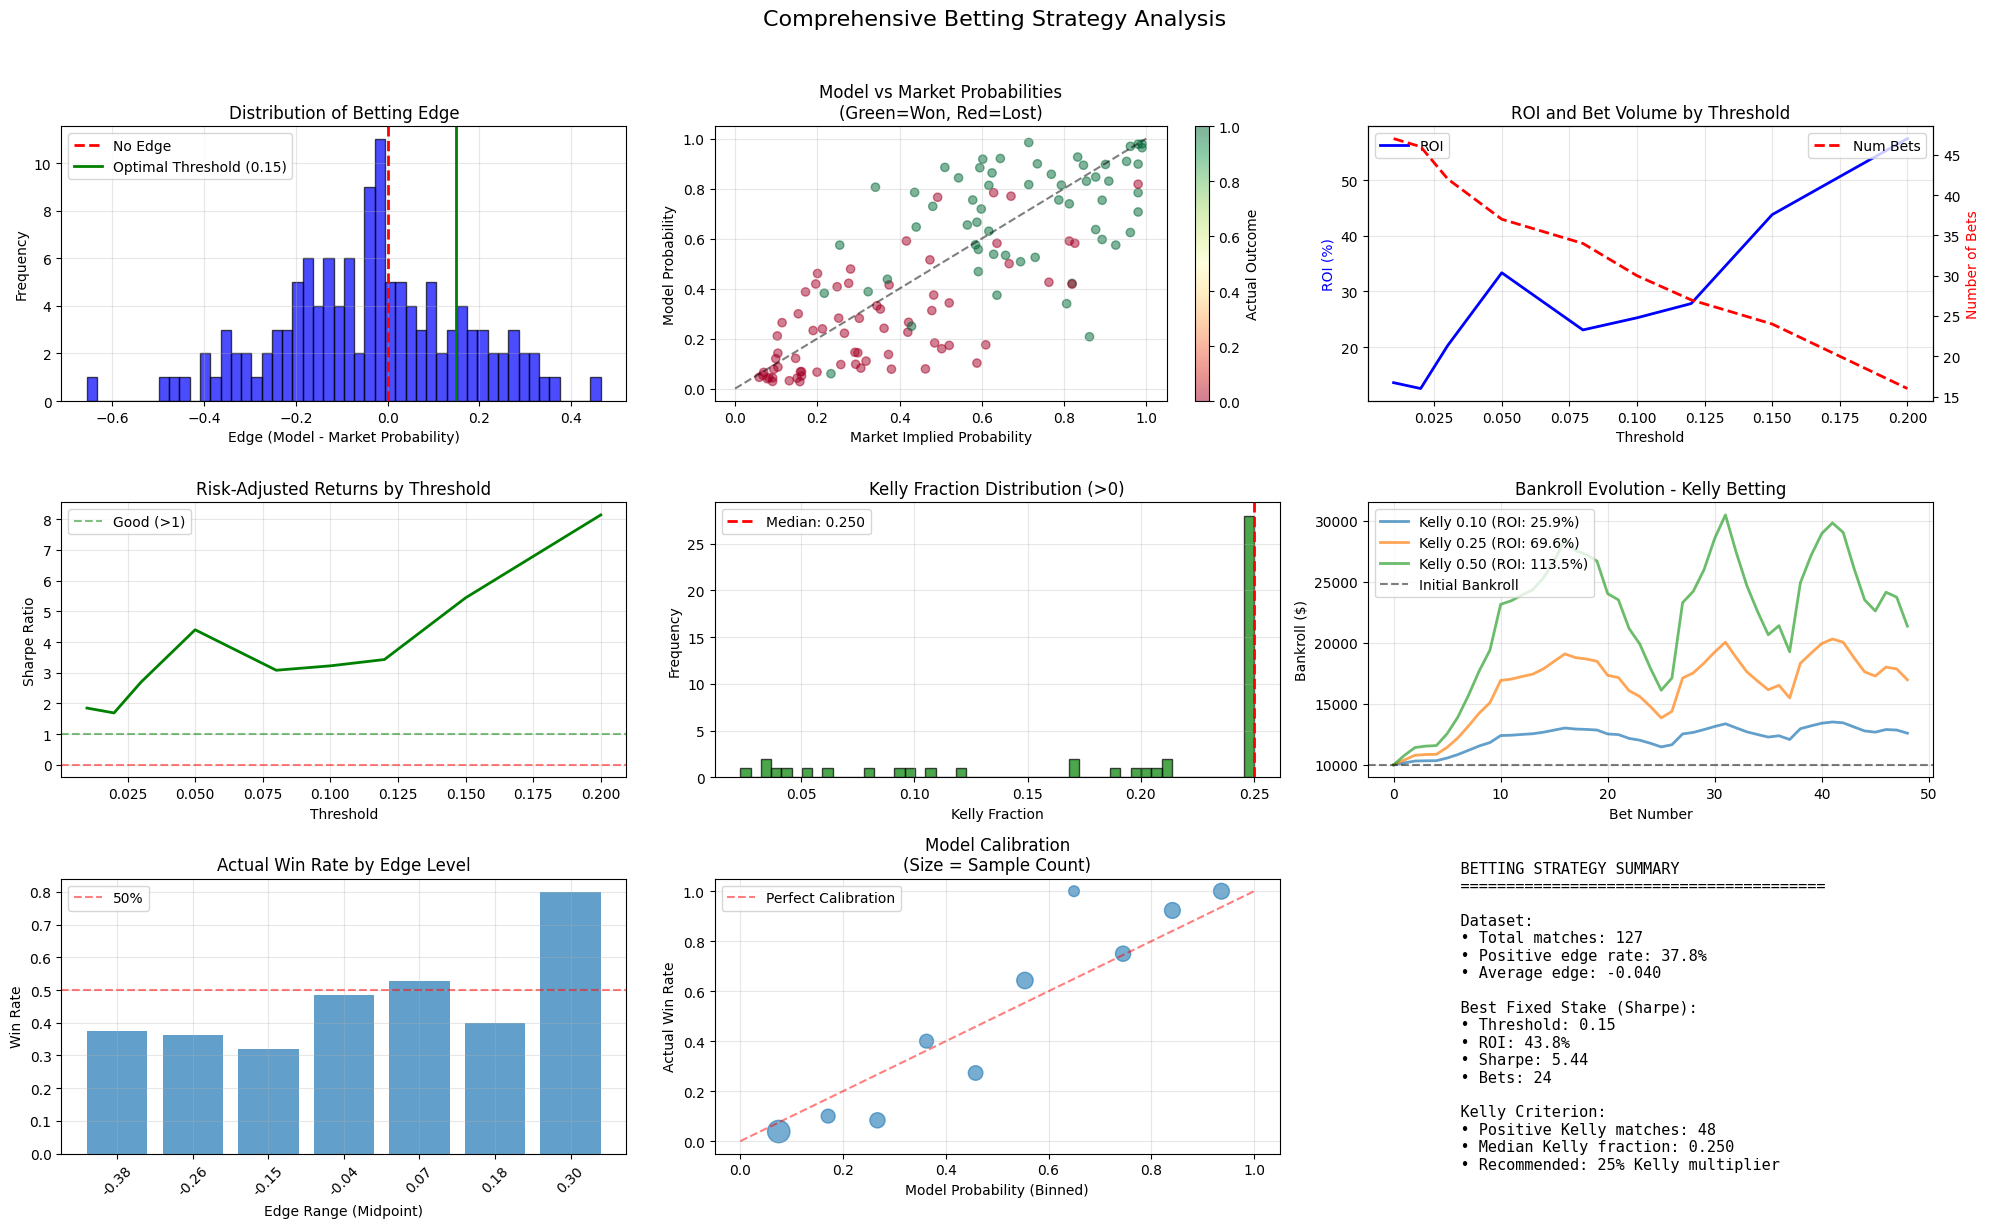

In [77]:
import sys
import os
import importlib

sys.path.append(os.path.abspath("../src/"))

# Force reload to pick up latest version of the module
if 'betting_func' in sys.modules:
    importlib.reload(sys.modules['betting_func'])

from betting_func import run_complete_betting_analysis

results = run_complete_betting_analysis(betting_df, tournament='Wimbledon')


In [86]:
import plotly.express as px
import plotly.graph_objects as go
fig1 = px.histogram(betting_df[betting_df['Tournament']=='Wimbledon'], x='edge', nbins=60, title='Edge Distribution by Actual Outcome')
fig1.update_traces(marker_line_color='black', marker_line_width=1)
fig1.show()

In [88]:
results['threshold_results']

,threshold,num_bets,total_profit,total_staked,roi,win_rate,sharpe_ratio,max_drawdown,avg_odds
0,0.01,47,640.0,4700,13.617021,0.574468,1.848971,900.0,3.224255
1,0.02,46,578.0,4600,12.565217,0.565217,1.690725,900.0,3.259130
2,0.03,42,852.0,4200,20.285714,0.595238,2.694435,700.0,3.091905
3,0.05,37,1234.0,3700,33.351351,0.648649,4.399079,500.0,2.946216
4,0.08,34,785.0,3400,23.088235,0.617647,3.081009,500.0,2.985882
5,0.10,30,758.0,3000,25.266667,0.600000,3.224422,500.0,3.192000
6,0.12,27,751.0,2700,27.814815,0.592593,3.429808,400.0,3.071852
7,0.15,24,1051.0,2400,43.791667,0.666667,5.438665,400.0,2.668750
8,0.20,16,919.0,1600,57.437500,0.750000,8.139618,300.0,2.696875


In [110]:
fig2 = go.Figure()

# ROI trace (primary y-axis)
fig2.add_trace(
    go.Scatter(
        x=results['threshold_results']['threshold'],
        y=results['threshold_results']['roi'],
        mode='lines+markers',
        name='ROI (%)',
        line=dict(color="#5997c3", width=2.5),
        marker=dict(size=6, color='#1f77b4', line=dict(color='white', width=1)),
        hovertemplate='Threshold: %{x:.2f}<br>ROI: %{y:.2f}%<extra></extra>'
    )
)

# Number of bets trace (secondary y-axis)
fig2.add_trace(
    go.Scatter(
        x=results['threshold_results']['threshold'],
        y=results['threshold_results']['num_bets'],
        mode='lines+markers',
        yaxis='y2',
        name='Number of Bets',
        line=dict(color='#d62728', width=2, dash='dash'),
        marker=dict(size=5.5, color='#d62728', symbol='diamond', line=dict(color='white', width=1)),
        hovertemplate='Threshold: %{x:.2f}<br>Bets: %{y:.0f}<extra></extra>'
    )
)

best_idx = results['threshold_results']['roi'].idxmax()
best_t = results['threshold_results'].loc[best_idx, 'threshold']
best_roi = results['threshold_results'].loc[best_idx, 'roi']

fig2.update_layout(
    title=dict(
        text='ROI vs Number of Bets by Edge Threshold',
        x=0.5,
        xanchor='center',
        font=dict(size=16)
    ),
    template='plotly_white',
    width=760,
    height=430,
    hovermode='x unified',
    font=dict(size=11),
    xaxis=dict(
        title='Edge Threshold',
        tickformat='.2f',
        gridcolor='rgba(0,0,0,0.08)',
        zeroline=False
    ),
    yaxis=dict(
        title='ROI (%)',
        tickformat='.1f',
        gridcolor='rgba(0,0,0,0.08)',
        zeroline=True,
        zerolinecolor='rgba(0,0,0,0.30)'
    ),
    yaxis2=dict(
        title='Number of Bets',
        overlaying='y',
        side='right',
        showgrid=False
    ),
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=1.01,
        xanchor='right',
        x=1
    ),
    margin=dict(l=55, r=55, t=70, b=50)
 )

# Highlight best ROI threshold
fig2.add_vline(
    x=best_t,
    line_dash='dot',
    line_color='#2ca02c',
    line_width=1.8
)
fig2.add_annotation(
    x=best_t,
    y=best_roi,
    text=f'Best ROI at {best_t:.2f}',
    showarrow=True,
    arrowhead=2,
    ax=22,
    ay=-28,
    bgcolor='rgba(255,255,255,0.9)',
    bordercolor='#2ca02c',
    font=dict(size=10)
)

fig2.show()